## Problema y objetivos

La empresa quiere identificar el género de una canción a partir de sus características de audio. La variable `id_genero` no es una etiqueta de sí o no, ni un valor numérico a estimar: toma 10 valores distintos y cada canción pertenece a una sola clase. El problema es de **clasificación supervisada multiclase**.

En este notebook el objetivo es entrenar un KNN y un Naive Bayes que, a partir de las características de 30 segundos de cada canción, le asignen una de esas 10 clases, y comparar ambos sobre el mismo problema. Los modelos se ajustan solo con las canciones de entrenamiento; el conjunto de test se reserva para la evaluación. El resultado se mide con accuracy y F1 macro, para ver el acierto global y el rendimiento medio entre géneros.

## Selección de métricas y umbral

**Accuracy.** Hay 10 géneros y el mismo número de canciones en cada clase. Con ese reparto equilibrado, el porcentaje de aciertos resume el rendimiento global sin que una clase más frecuente lo distorsione.

**F1 macro.** Se calcula el F1 de cada género y se promedia dando el mismo peso a las 10 clases. Así, un género fácil de clasificar no compensa a otro que el modelo confunde. El F1 por clase del informe de clasificación muestra cuáles son esos géneros.

**Umbral de decisión.** El modelo devuelve una probabilidad para cada una de las 10 clases. La clase asignada es la de probabilidad más alta. No se exige una probabilidad mínima para aceptar la predicción: si la clase ganadora tiene, por ejemplo, 0,2 y el resto queda por debajo, esa clase se predice igualmente.

In [ ]:
import pandas as pd
import numpy as np
import random
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

from sklearn.naive_bayes import GaussianNB

In [ ]:
from pathlib import Path

def carpeta_proyecto(nombre, marca):
    """Localiza los CSV en Jupyter, Visual Studio Code y Colab."""
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    bases.append(Path.cwd().resolve())
    content = Path("/content")
    if content.is_dir():
        bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir():
            bases.append(drive)

    nombradas = []
    sueltas = []
    vistos = set()

    def considerar(directorio, aceptar_suelto):
        if directorio in vistos:
            return
        vistos.add(directorio)
        try:
            carpeta = directorio / nombre
            if (carpeta / marca).is_file():
                nombradas.append(carpeta)
                return
            if directorio.name == nombre and (directorio / marca).is_file():
                nombradas.append(directorio)
                return
            if aceptar_suelto and (directorio / marca).is_file():
                sueltas.append(directorio)
        except OSError:
            return

    def hijos(directorio, profundidad, limite):
        if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
            return
        try:
            entradas = list(directorio.iterdir())
        except OSError:
            return
        for hijo in entradas:
            if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                continue
            limite[0] -= 1
            considerar(hijo, False)
            if nombradas or limite[0] <= 0:
                return
            hijos(hijo, profundidad - 1, limite)
            if nombradas or limite[0] <= 0:
                return

    for base in bases:
        considerar(base, True)
        if nombradas:
            break
        for padre in list(base.parents)[:6]:
            considerar(padre, False)
            if nombradas:
                break
        if nombradas:
            break
        profundidad = 3 if base.name in {"content", "MyDrive"} else 2
        hijos(base, profundidad, [400])
        if nombradas:
            break

    if nombradas:
        return nombradas[0]
    if sueltas:
        return sueltas[0]
    raise FileNotFoundError(
        "No se encuentra " + marca + ". "
        "Tiene que existir la carpeta '" + nombre + "' en el proyecto, "
        "o el archivo en el directorio de trabajo. En Colab puede estar junto a sample_data."
    )


def carpeta_datos():
    """Carpeta datos preprocesados, en Jupyter, Visual Studio Code o Colab."""
    return carpeta_proyecto("datos preprocesados", "ids_train.csv")

DATOS = carpeta_datos()
print("Datos:", DATOS)

# Cargar dataset
df = pd.read_csv(DATOS / "df_cancion_30s.csv")

In [ ]:
df

,id_cancion,cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica,filename_30s,length_30s,...,mfcc16_var_30s,mfcc17_mean_30s,mfcc17_var_30s,mfcc18_mean_30s,mfcc18_var_30s,mfcc19_mean_30s,mfcc19_var_30s,mfcc20_mean_30s,mfcc20_var_30s,label_30s
0,1,blues.00000.wav,138.0,744.01,1,1,1,1,blues.00000.wav,661794,...,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,2,blues.00001.wav,142.0,4178.85,1,2,2,2,blues.00001.wav,661794,...,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,3,blues.00002.wav,96.0,3226.40,1,3,4,3,blues.00002.wav,661794,...,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,4,blues.00003.wav,111.0,3618.77,1,4,6,4,blues.00003.wav,661794,...,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,5,blues.00004.wav,191.0,1990.81,1,5,7,5,blues.00004.wav,661794,...,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,rock.00095.wav,101.0,3185.88,10,197,306,25,rock.00095.wav,661794,...,45.050526,-13.289984,41.754955,2.484145,36.778877,-6.713265,54.866825,-1.193787,49.950665,rock
996,997,rock.00096.wav,170.0,-503.65,10,194,321,1,rock.00096.wav,661794,...,33.851742,-10.848309,39.395096,1.881229,32.010040,-7.461491,39.196327,-2.795338,31.773624,rock
997,998,rock.00097.wav,121.0,2170.05,10,189,297,9,rock.00097.wav,661794,...,33.597008,-12.845291,36.367264,3.440978,36.001110,-12.588070,42.502201,-2.106337,29.865515,rock
998,999,rock.00098.wav,99.0,1425.79,10,187,301,20,rock.00098.wav,661794,...,46.324894,-4.416050,43.583942,1.556207,34.331261,-5.041897,47.227180,-3.590644,41.299088,rock


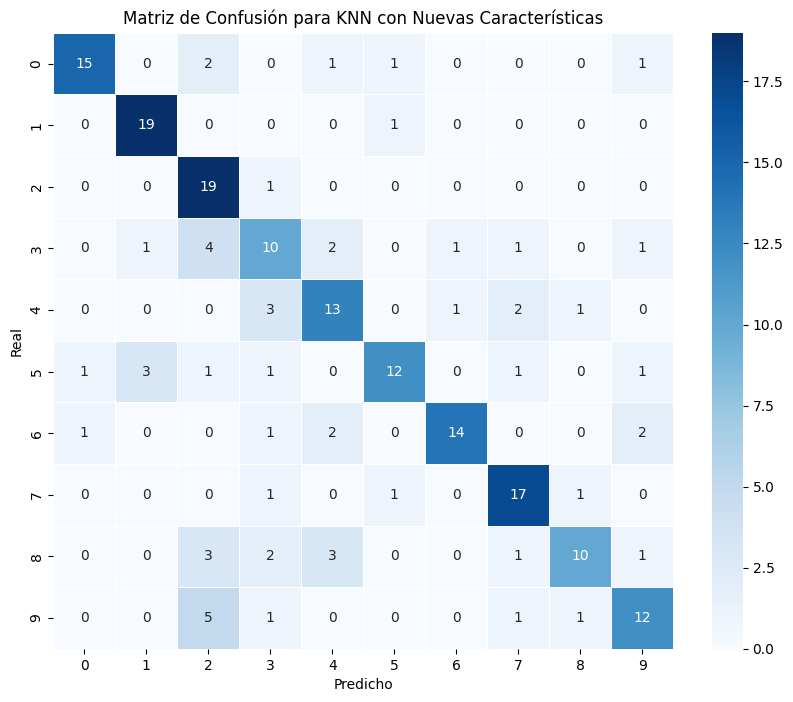

Accuracy (KNN con Nuevas Características): 0.705

Reporte de Clasificación (KNN con Nuevas Características):
              precision    recall  f1-score   support

           1       0.88      0.75      0.81        20
           2       0.83      0.95      0.88        20
           3       0.56      0.95      0.70        20
           4       0.50      0.50      0.50        20
           5       0.62      0.65      0.63        20
           6       0.80      0.60      0.69        20
           7       0.88      0.70      0.78        20
           8       0.74      0.85      0.79        20
           9       0.77      0.50      0.61        20
          10       0.67      0.60      0.63        20

    accuracy                           0.70       200
   macro avg       0.72      0.70      0.70       200
weighted avg       0.72      0.70      0.70       200



In [ ]:
from pathlib import Path

def carpeta_proyecto(nombre, marca):
    """Localiza los CSV en Jupyter, Visual Studio Code y Colab."""
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    bases.append(Path.cwd().resolve())
    content = Path("/content")
    if content.is_dir():
        bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir():
            bases.append(drive)

    nombradas = []
    sueltas = []
    vistos = set()

    def considerar(directorio, aceptar_suelto):
        if directorio in vistos:
            return
        vistos.add(directorio)
        try:
            carpeta = directorio / nombre
            if (carpeta / marca).is_file():
                nombradas.append(carpeta)
                return
            if directorio.name == nombre and (directorio / marca).is_file():
                nombradas.append(directorio)
                return
            if aceptar_suelto and (directorio / marca).is_file():
                sueltas.append(directorio)
        except OSError:
            return

    def hijos(directorio, profundidad, limite):
        if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
            return
        try:
            entradas = list(directorio.iterdir())
        except OSError:
            return
        for hijo in entradas:
            if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                continue
            limite[0] -= 1
            considerar(hijo, False)
            if nombradas or limite[0] <= 0:
                return
            hijos(hijo, profundidad - 1, limite)
            if nombradas or limite[0] <= 0:
                return

    for base in bases:
        considerar(base, True)
        if nombradas:
            break
        for padre in list(base.parents)[:6]:
            considerar(padre, False)
            if nombradas:
                break
        if nombradas:
            break
        profundidad = 3 if base.name in {"content", "MyDrive"} else 2
        hijos(base, profundidad, [400])
        if nombradas:
            break

    if nombradas:
        return nombradas[0]
    if sueltas:
        return sueltas[0]
    raise FileNotFoundError(
        "No se encuentra " + marca + ". "
        "Tiene que existir la carpeta '" + nombre + "' en el proyecto, "
        "o el archivo en el directorio de trabajo. En Colab puede estar junto a sample_data."
    )


def carpeta_datos():
    """Carpeta datos preprocesados, en Jupyter, Visual Studio Code o Colab."""
    return carpeta_proyecto("datos preprocesados", "ids_train.csv")

DATOS = carpeta_datos()
print("Datos:", DATOS)

import pandas as pd
import numpy as np
import random
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix



# Cargar IDs de entrenamiento y prueba
train_ids = pd.read_csv(DATOS / "ids_train.csv")
test_ids = pd.read_csv(DATOS / "ids_test.csv")

# Asegurarse de que las columnas de ID estén en el formato correcto si es necesario (ej. 'id_cancion')
# Asumiendo que ambos CSVs de IDs tienen una columna llamada 'id_cancion'

# Filtrar el DataFrame principal para crear los conjuntos de entrenamiento y prueba
df_train = df[df['id_cancion'].isin(train_ids['id_cancion'])]
df_test = df[df['id_cancion'].isin(test_ids['id_cancion'])]

# Definir las nuevas características a usar
features = [
    "coste",
    "length_30s",
    "chroma_stft_mean_30s", "chroma_stft_var_30s",
    "rms_mean_30s", "rms_var_30s",
    "spectral_centroid_mean_30s", "spectral_centroid_var_30s",
    "spectral_bandwidth_mean_30s", "spectral_bandwidth_var_30s",
    "rolloff_mean_30s", "rolloff_var_30s",
    "zero_crossing_rate_mean_30s", "zero_crossing_rate_var_30s",
    "harmony_mean_30s", "harmony_var_30s",
    "perceptr_mean_30s", "perceptr_var_30s",
    "tempo_30s",
    "mfcc1_mean_30s", "mfcc1_var_30s",
    "mfcc2_mean_30s", "mfcc2_var_30s",
    "mfcc3_mean_30s", "mfcc3_var_30s",
    "mfcc4_mean_30s", "mfcc4_var_30s",
    "mfcc5_mean_30s", "mfcc5_var_30s",
    "mfcc6_mean_30s", "mfcc6_var_30s",
    "mfcc7_mean_30s", "mfcc7_var_30s",
    "mfcc8_mean_30s", "mfcc8_var_30s",
    "mfcc9_mean_30s", "mfcc9_var_30s",
    "mfcc10_mean_30s", "mfcc10_var_30s",
    "mfcc11_mean_30s", "mfcc11_var_30s",
    "mfcc12_mean_30s", "mfcc12_var_30s",
    "mfcc13_mean_30s", "mfcc13_var_30s",
    "mfcc14_mean_30s", "mfcc14_var_30s",
    "mfcc15_mean_30s", "mfcc15_var_30s",
    "mfcc16_mean_30s", "mfcc16_var_30s",
    "mfcc17_mean_30s", "mfcc17_var_30s",
    "mfcc18_mean_30s", "mfcc18_var_30s",
    "mfcc19_mean_30s", "mfcc19_var_30s",
    "mfcc20_mean_30s", "mfcc20_var_30s"
]

X_train = df_train[features]
y_train = df_train["id_genero"]

X_test = df_test[features]
y_test = df_test["id_genero"]

# Escalar los datos de entrenamiento y prueba
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Crear modelo KNN
knn = KNeighborsClassifier(n_neighbors=4)

# Entrenar
knn.fit(X_train, y_train)

# Predicciones
y_pred = knn.predict(X_test)

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred);

# Crear el mapa de calor
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,      # Mostrar valores
    fmt='d',         # Formato entero
    cmap='Blues',    # Escala de colores
    linewidths=0.5
)
plt.title('Matriz de Confusión para KNN con Nuevas Características')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

# Evaluación
print(f"Accuracy (KNN con Nuevas Características): {accuracy_score(y_test, y_pred)}")
print("\nReporte de Clasificación (KNN con Nuevas Características):")
print(classification_report(y_test, y_pred))

El modelo KNN, con 4 vecinos y las características de 30 segundos, alcanza un accuracy del 70,5 % y un F1 macro de 0,70 en las 200 canciones de prueba.

En el classification report destacan las clases 2, 1 y 8 (F1 0,88, 0,81 y 0,79). La clase 4 queda en 0,50. El conjunto de prueba está equilibrado, con 20 canciones por género.

### Algoritmo Naive Bayes

Ahora implementaremos un clasificador Naive Bayes para comparar su rendimiento con el modelo KNN.

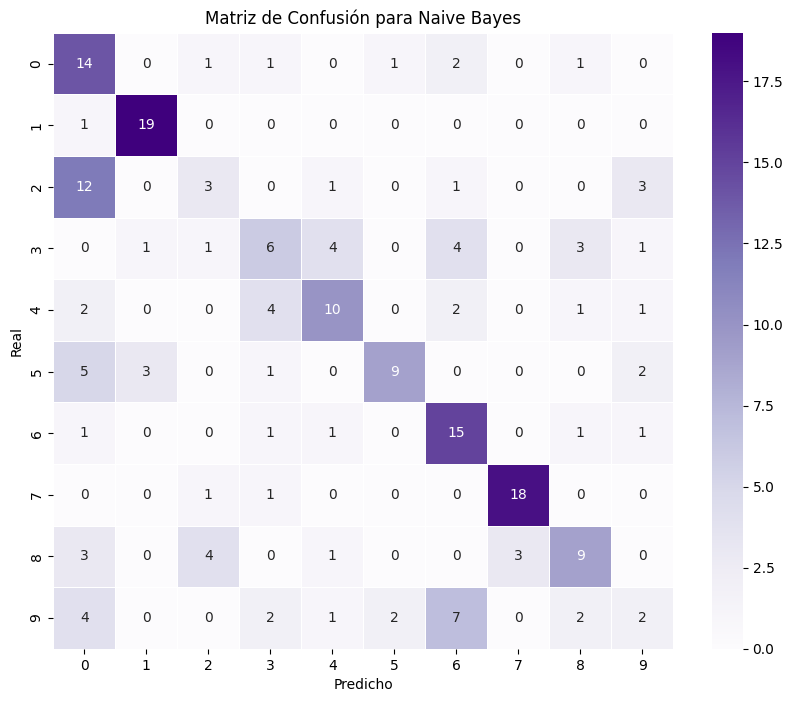

Accuracy (Naive Bayes): 0.525

Reporte de Clasificación (Naive Bayes):
              precision    recall  f1-score   support

           1       0.33      0.70      0.45        20
           2       0.83      0.95      0.88        20
           3       0.30      0.15      0.20        20
           4       0.38      0.30      0.33        20
           5       0.56      0.50      0.53        20
           6       0.75      0.45      0.56        20
           7       0.48      0.75      0.59        20
           8       0.86      0.90      0.88        20
           9       0.53      0.45      0.49        20
          10       0.20      0.10      0.13        20

    accuracy                           0.53       200
   macro avg       0.52      0.52      0.50       200
weighted avg       0.52      0.53      0.50       200



In [ ]:


# Crear modelo Naive Bayes (GaussianNB es adecuado para datos continuos y escalados)
naive_bayes = GaussianNB()

# Entrenar el modelo
naive_bayes.fit(X_train, y_train)

# Predicciones
y_pred_nb = naive_bayes.predict(X_test)

# Matriz de confusión para Naive Bayes
cm_nb = confusion_matrix(y_test, y_pred_nb);

# Crear el mapa de calor para Naive Bayes
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_nb,
    annot=True,      # Mostrar valores
    fmt='d',         # Formato entero
    cmap='Purples',  # Escala de colores diferente para distinguirlo
    linewidths=0.5
)
plt.title('Matriz de Confusión para Naive Bayes')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

# Evaluación de Naive Bayes
print("Accuracy (Naive Bayes):", accuracy_score(y_test, y_pred_nb))
print("\nReporte de Clasificación (Naive Bayes):")
print(classification_report(y_test, y_pred_nb))

El modelo Naive Bayes obtuvo una accuracy del 52,5 %, lo que indica un rendimiento moderado en la clasificación porque clasifica correctamente el 52% de las veces.

Si observamos el F1-score vemos que las clases 2 y 8 tienen los mejores datos con un 0,88. Por el contrario la clase 3 y 10 representan los datos de rendimiento más bajo respectivamente con un F1-score de 0,20 y 0,13.

El rendimiento desigual entre las clases disponibles nos sugiere que el modelo puede tener problemas para la identificación de alguna de las clases.

